# 1. Import Library dan Modul


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sys
import os

# Memastikan folder src/ bisa dibaca oleh notebook
sys.path.append(os.path.abspath('../src'))

# Import 3 modul buatan kita
from preprocessing import SitanpasPreprocessor
from tfidf_engine import RetrievalEngine
from metrics import calculate_precision_at_k, calculate_recall, calculate_f1_score, calculate_mrr, calculate_hit_rate

print("Semua modul berhasil dimuat!")

Semua modul berhasil dimuat!


# 2. Load Dataset dan Corpus Ground Truth 

In [5]:
# Load dataset korpus (Katalog Produk)
df_produk = pd.read_csv('../data/south_ambesia_coastal_fishery_products.csv')

# Load dataset ground truth (Data Uji 20 Query)
df_ground_truth = pd.read_csv('../data/ground_truth_relevance.csv')

# Rename kolom agar sesuai dengan pipeline kita
df_ground_truth = df_ground_truth.rename(columns={
    'No': 'query_id', 
    'Query Uji': 'query'
})

print(f"Total Produk: {len(df_produk)}")
print(f"Total Query Uji: {df_ground_truth['query_id'].nunique()}")

Total Produk: 27
Total Query Uji: 20


# 3. Eksekusi Preprocessing

In [6]:
# Inisialisasi Preprocessor
preprocessor = SitanpasPreprocessor()

# 1. Preprocessing Korpus (Gabung Nama + Kategori + Deskripsi)
print("Sedang memproses korpus dokumen...")
df_produk['processed_text'] = df_produk.apply(preprocessor.create_document_feature, axis=1)

# 2. Preprocessing Query pada Ground Truth
print("Sedang memproses query...")
df_ground_truth['processed_query'] = df_ground_truth['query'].apply(preprocessor.preprocess)

print("Preprocessing selesai!")
df_produk[['nama_produk', 'processed_text']].head(3)

Sedang memproses korpus dokumen...
Sedang memproses query...
Preprocessing selesai!


,nama_produk,processed_text
0,Cumi Pena,cumi pena cumi cumi cumi kecil panjang panjang
1,Ikan Barakuda,barakuda barakuda ukur sedang
2,Ikan Cakalang,cakalang cakalang besar


# 4. Inisialisasi Mesin IR (TF-IDF, Cosine, Jaccard, BM25)

In [7]:
# Inisialisasi Retrieval Engine
engine = RetrievalEngine(corpus_df=df_produk, document_col='processed_text', id_col='product_id')

print("Mesin pencarian (TF-IDF, Cosine, Jaccard, BM25) berhasil dirakit dan siap digunakan!")

Mesin pencarian (TF-IDF, Cosine, Jaccard, BM25) berhasil dirakit dan siap digunakan!


# 5. Proses Evaluasi Masal

In [8]:
# Daftar algoritma yang akan diadu
methods = ['cosine', 'jaccard', 'bm25']
results_list = []

for method in methods:
    for index, row in df_ground_truth.iterrows():
        query_id = row['query_id']
        raw_query = row['query']
        processed_query = row['processed_query']
        
        # Ekstrak Product IDs Relevan dari format string yang dipisahkan koma
        relevant_docs_str = str(row['Product IDs Relevan'])
        # Hilangkan spasi dan tanda kutip, lalu split berdasarkan koma
        relevant_docs = [doc_id.strip().replace('"', '') for doc_id in relevant_docs_str.split(',')]
        
        # Jalankan pencarian menggunakan mesin kita (top_n = 10, threshold = 0.34)
        retrieved_results = engine.retrieve(processed_query, method=method, threshold=0.34, top_n=10)
        retrieved_docs = [res['product_id'] for res in retrieved_results]
        
        # Hitung Metrik
        precision = calculate_precision_at_k(retrieved_docs, relevant_docs, k=10)
        recall = calculate_recall(retrieved_docs, relevant_docs)
        f1 = calculate_f1_score(precision, recall)
        mrr = calculate_mrr(retrieved_docs, relevant_docs)
        hit_rate = calculate_hit_rate(retrieved_docs, relevant_docs)
        
        # Simpan hasil
        results_list.append({
            'Method': method.upper(),
            'Query_ID': query_id,
            'Query': raw_query,
            'Precision': precision,
            'Recall': recall,
            'F1_Score': f1,
            'MRR': mrr,
            'Hit_Rate': hit_rate
        })

# Jadikan DataFrame
df_eval = pd.DataFrame(results_list)

# Kalkulasi rata-rata (Mean) untuk setiap algoritma
eval_summary = df_eval.groupby('Method')[['Precision', 'Recall', 'F1_Score', 'MRR', 'Hit_Rate']].mean().reset_index()
display(eval_summary)

,Method,Precision,Recall,F1_Score,MRR,Hit_Rate
0,BM25,0.460119,0.631250,0.499286,0.65,0.65
1,COSINE,0.559167,0.550000,0.512024,0.65,0.65
2,JACCARD,0.337500,0.233333,0.259524,0.35,0.35


# 6. Visualisasi Grafik Komparasi Algoritma

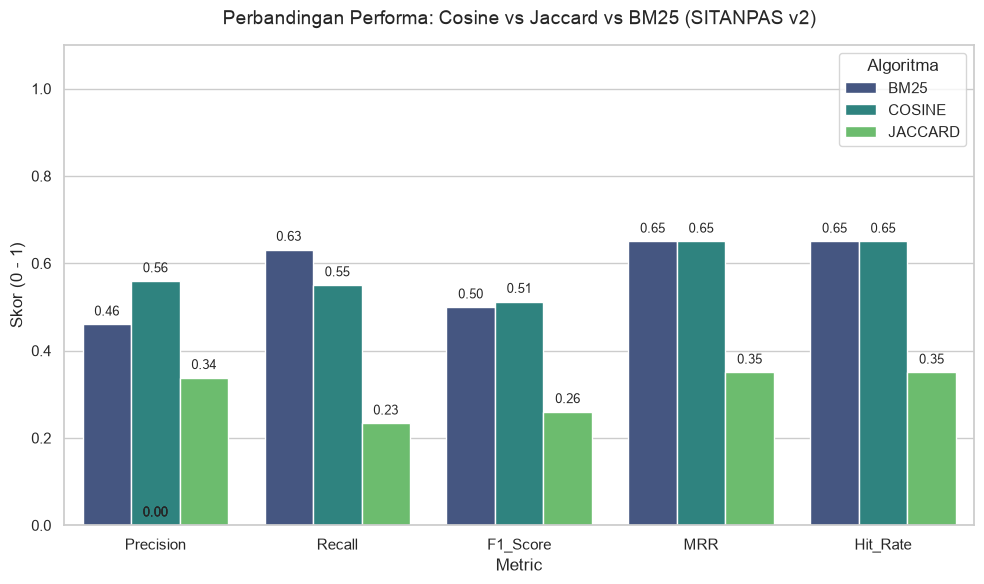

In [9]:
# Setup grafik menggunakan Seaborn
plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")

# Melt dataframe agar mudah diplot
df_melted = eval_summary.melt(id_vars="Method", var_name="Metric", value_name="Score")

# Render Bar Chart
ax = sns.barplot(x="Metric", y="Score", hue="Method", data=df_melted, palette="viridis")
plt.title("Perbandingan Performa: Cosine vs Jaccard vs BM25 (SITANPAS v2)", fontsize=14, pad=15)
plt.ylabel("Skor (0 - 1)")
plt.ylim(0, 1.1)

# Tambahkan label angka di atas bar
for p in ax.patches:
    ax.annotate(format(p.get_height(), '.2f'), 
                (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha = 'center', va = 'center', 
                xytext = (0, 9), 
                textcoords = 'offset points',
                fontsize=9)

plt.legend(title="Algoritma")
plt.tight_layout()
plt.show()